In [27]:
import seaborn
from scipy.special import softmax, log_softmax
from numpy.lib.stride_tricks import sliding_window_view
import scipy.stats as stats
import pickle
import json
from pathlib import Path
import warnings
import torch
import re
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
from seaborn import kdeplot
from tqdm.auto import tqdm
from scipy.stats import gmean


def meanprob(answer_probabilities):
    return gmean([next(iter(value.values())) for value in answer_probabilities])


def is_same_literal_regex(x, y):
    # Remove anything that isn't a letter or a number
    clean_x = re.sub(r'[^a-zA-Z0-9]', '', x).upper()
    clean_y = re.sub(r'[^a-zA-Z0-9]', '', y).upper()
    
    return clean_x == clean_y

In [42]:
sample_filepaths = {}
# sample_filepaths['movie_llama_pregen'] = Path("../Chain-of-thought_trajectories/trajectories/debug-0402-top-10-llama_llama_llama_8b_31_bigbench_movie_recommendation_0_250_conf_jackknife")
# sample_filepaths['movie_llama_gen1'] = Path("../Chain-of-thought_trajectories/trajectories/406-llama-type1_llama_regular_bigbench_movie_zero_0_250_type1_conf_jackknife")
# sample_filepaths['movie_llama_gen2'] = Path("../Chain-of-thought_trajectories/trajectories/406-llama-type2_llama_regular_bigbench_movie_zero_0_250_type2_conf_jackknife")
sample_filepaths['movie_llama_gen1_box'] = Path("./trajectories/4010_llama-boxed-type1_llama_regular_bigbench_movie_zero_0_250_type1_conf_jackknife")
sample_filepaths['movie_llama_gen2_box'] = Path("./trajectories/4010_llama-boxed-type2_llama_regular_bigbench_movie_zero_0_250_type2_conf_jackknife")
# sample_filepaths['movie_qwen_gen1'] = Path("../Chain-of-thought_trajectories/trajectories/406-qwen-type1_qwen_regular_bigbench_movie_zero_0_250_type1_conf_jackknife")
# sample_filepaths['movie_qwen_gen2'] = Path("../Chain-of-thought_trajectories/trajectories/406-qwen-type2_qwen_regular_bigbench_movie_zero_0_250_type2_conf_jackknife")

In [43]:
confidences = defaultdict(lambda: defaultdict(list))
nb_steps = defaultdict(list)
nb_jackknifes = defaultdict(list)
generated_text = defaultdict(list)
for dataset in sample_filepaths:
    print(f"Loading {dataset}")
    trajectories = []
    sample_files = list(sample_filepaths[dataset].glob("traj_*.json"))
    for sample_file in tqdm(sample_files):
        with open(sample_file, "r") as file:
            trajectories += [json.load(file)]
    
    for trajectory in tqdm(trajectories):
        traj_conf = trajectory['trajectory']['confidence_score']
        if traj_conf is not None:
            generated_text[dataset] += [trajectory['trajectory']['generated_text']]
            nb_steps[dataset] += [len(trajectory['trajectory']['cot_steps'])]
            confidences[dataset]['accuracy'] += [is_same_literal_regex(trajectory['trajectory']['final_answer'], 
                                                                       trajectory['trajectory']['ground_truth'])]
            confidences[dataset]['vanilla_meanprob'] += [meanprob(traj_conf['vanilla_confidences']['answer_probabilities'])]
            confidences[dataset]['jackknife_meanprob'] += [[meanprob(confidence) for confidence in traj_conf['jackknife_confidences']['answer_probabilities']]]
            confidences[dataset]['vanilla_meanent'] += [np.exp(-meanprob(traj_conf['vanilla_confidences']['answer_entropy']))]
            confidences[dataset]['jackknife_meanent'] += [[np.exp(-meanprob(confidence)) for confidence in traj_conf['jackknife_confidences']['answer_entropy']]]
            confidences[dataset]['vanilla_indirect1'] += [traj_conf['vanilla_confidences']['indirect_ptrue1_probabilities'][0]['True']]
            confidences[dataset]['jackknife_indirect1'] += [[confidence['True'] for confidence in traj_conf['jackknife_confidences']['indirect_ptrue1_probabilities']]]
            confidences[dataset]['vanilla_indirect2'] += [traj_conf['vanilla_confidences']['indirect_ptrue2_probabilities'][0]['Yes']]
            confidences[dataset]['jackknife_indirect2'] += [[confidence['Yes'] for confidence in traj_conf['jackknife_confidences']['indirect_ptrue2_probabilities']]]
            confidences[dataset]['vanilla_indirect3'] += [traj_conf['vanilla_confidences']['indirect_ptrue3_probabilities'][0]['Yes']]
            confidences[dataset]['jackknife_indirect3'] += [[confidence['Yes'] for confidence in traj_conf['jackknife_confidences']['indirect_ptrue3_probabilities']]]
            confidences[dataset]['vanilla_verbal'] += [traj_conf['vanilla_confidences']['verbconf_probabilities'][0]]
            confidences[dataset]['jackknife_verbal'] += [traj_conf['jackknife_confidences']['verbconf_probabilities']]
    
    nb_steps[dataset] = torch.LongTensor(nb_steps[dataset])
    nb_jackknifes[dataset] = torch.ceil(torch.sqrt(nb_steps[dataset]))
    for key in confidences[dataset]:
        confidences[dataset][key] = torch.FloatTensor(confidences[dataset][key])

Loading movie_llama_gen1_box


100%|███████████████████████████████████████████████████████████████████████████████████████████| 196/196 [00:00<00:00, 322.58it/s]


Loading movie_llama_gen2_box


100%|███████████████████████████████████████████████████████████████████████████████████████████| 225/225 [00:00<00:00, 290.65it/s]


In [30]:
raise ValueError()
for key in generated_text:
    print(key+f'\n---------------\n')
    print(generated_text[key][1])
    print('\n\n')

ValueError: 

tensor(217.)

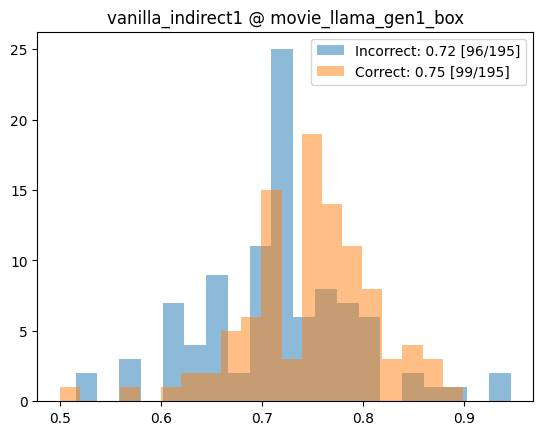

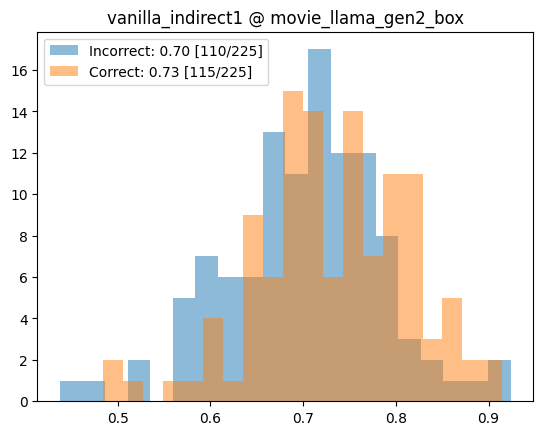

In [64]:
confidence_type = 'vanilla_indirect1'
# confidence_type = 'jackknife_meanprob'
for dataset in confidences:
    x = confidences[dataset][confidence_type][~confidences[dataset]['accuracy'].bool()]#.clip(1e-5,1-1e-5).logit()
    plt.hist(x, alpha=0.5, bins=20, label=f"Incorrect: {x.mean():.2f}"
             f" [{(1-confidences[dataset]['accuracy']).sum().long()}/{len(confidences[dataset]['accuracy'])}]")
    x = confidences[dataset][confidence_type][confidences[dataset]['accuracy'].bool()]#.clip(1e-5,1-1e-5).logit()
    plt.hist(x, alpha=0.5, bins=20, label=f"Correct: {x.mean():.2f}"
             f" [{confidences[dataset]['accuracy'].sum().long()}/{len(confidences[dataset]['accuracy'])}]")
    plt.legend()
    plt.title(f"{confidence_type} @ {dataset}")
    plt.show()